In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os

INPUT_DIR = "/kaggle/input"

for root, dirs, files in os.walk(INPUT_DIR):
    level = root.replace(INPUT_DIR, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    print(f"\n📁 {root}")
    for file in files[:10]:
        print(f"   {file}")


📁 /kaggle/input

📁 /kaggle/input/datasets

📁 /kaggle/input/datasets/prajaktananda1905


In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(f"\n📁 {root}")
    print(f"   Files: {len(files)}")
    for f in files[:8]:
        print(f"   - {f}")


📁 /kaggle/input
   Files: 0

📁 /kaggle/input/datasets
   Files: 0

📁 /kaggle/input/datasets/prajaktananda1905
   Files: 0

📁 /kaggle/input/datasets/prajaktananda1905/amr-data
   Files: 0

📁 /kaggle/input/datasets/prajaktananda1905/amr-data/data
   Files: 0

📁 /kaggle/input/datasets/prajaktananda1905/amr-data/data/genomes
   Files: 1138
   - 1280.15865.fna
   - 1280.15866.fna
   - 1280.15867.fna
   - 1280.15868.fna
   - 1280.15869.fna
   - 1280.15871.fna
   - 1280.15872.fna
   - 1280.15873.fna

📁 /kaggle/input/datasets/prajaktananda1905/amr-data/data/processed
   Files: 3
   - bvbrc_availability_audit.csv
   - ciprofloxacin_genome_level.csv
   - genome_retrieval_manifest.csv

📁 /kaggle/input/datasets/prajaktananda1905/amr-data/data/raw
   Files: 1
   - S.aureus_ciprofloxacin_broth_dilution.xlsx


In [3]:
import pandas as pd
import os

DATA_DIR = "/kaggle/input/datasets/prajak tananda1905/amr-data/data"

In [4]:
import glob
import pandas as pd

csv_path = glob.glob(
    "/kaggle/input/**/ciprofloxacin_genome_level.csv",
    recursive=True
)[0]

df = pd.read_csv(csv_path)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())

Shape: (1205, 3)

Columns:
['Genome ID', 'Phenotype', 'Label']

First 5 rows:


,Genome ID,Phenotype,Label
0,1280.15865,"('Susceptible',)",0
1,1280.15866,"('Susceptible',)",0
2,1280.15867,"('Susceptible',)",0
3,1280.15868,"('Susceptible',)",0
4,1280.15869,"('Susceptible',)",0


In [5]:
import glob
import os

genome_files = glob.glob(
    "/kaggle/input/**/genomes/*.fna",
    recursive=True
)

df["Genome ID"] = df["Genome ID"].astype(str)

fasta_ids = {
    os.path.basename(f).replace(".fna", "")
    for f in genome_files
}

csv_ids = set(df["Genome ID"])

print("FASTA files:", len(fasta_ids))
print("CSV rows:", len(df))
print("Unique CSV genome IDs:", df["Genome ID"].nunique())
print("Duplicate CSV rows:", df["Genome ID"].duplicated().sum())
print("IDs without FASTA:", len(csv_ids - fasta_ids))
print("FASTA IDs without CSV entry:", len(fasta_ids - csv_ids))

print("\nLabel distribution:")
print(df["Label"].value_counts())

print("\nDuplicate examples:")
display(df[df["Genome ID"].duplicated(keep=False)].head(10))

FASTA files: 1138
CSV rows: 1205
Unique CSV genome IDs: 1205
Duplicate CSV rows: 0
IDs without FASTA: 67
FASTA IDs without CSV entry: 0

Label distribution:
Label
0    691
1    514
Name: count, dtype: int64

Duplicate examples:


,Genome ID,Phenotype,Label


# DNABERT-2: Genome Representation Learning for Antimicrobial Resistance Prediction

## 1. Objective

The objective of this experiment is to investigate whether pretrained DNA language model representations can capture genomic patterns associated with ciprofloxacin resistance in *Staphylococcus aureus*.

We use the pretrained DNABERT-2 (117M) model to generate genome-level embeddings from whole-genome sequences. These embeddings are subsequently used as input features for a downstream machine learning classifier.

## 2. Dataset Preparation

The dataset consists of *Staphylococcus aureus* genomes obtained from BV-BRC, with ciprofloxacin susceptibility phenotypes.

- Organism: *Staphylococcus aureus*
- Taxon ID: 1280
- Antibiotic: Ciprofloxacin
- Phenotype labels:
  - 0: Susceptible
  - 1: Resistant

The processed phenotype table contained 1,205 genome records. However, only 1,138 corresponding genome FASTA files were available.

Therefore, 1,138 genomes with both sequence data and phenotype labels were retained for this experiment.

## 3. Pretrained DNABERT-2 Model

The original pretrained checkpoint, `zhihan1996/DNABERT-2-117M`, was loaded using Hugging Face Transformers.

Model configuration:
- Architecture: DNABERT-2
- Parameters: Approximately 117 million
- Transformer layers: 12
- Hidden representation dimension: 768
- Execution device: NVIDIA GPU

The pretrained model was used as a frozen feature extractor. No model fine-tuning was performed during embedding extraction.

A compatibility adjustment was applied to bypass the custom Triton attention kernel and use the standard PyTorch attention implementation.

## 4. Genome Segmentation and Sampling

Since bacterial genomes are substantially longer than the model's input capacity, each genome was divided into smaller DNA segments.

The following sampling strategy was implemented:

- Window length: 1,000 base pairs
- Target windows per genome: 16
- Sampling distribution: Proportional to contig length
- Sampling locations: Distributed across individual contigs
- Invalid windows containing ambiguous nucleotide characters were excluded.

Sampling was performed independently for each genome, without joining separate contigs or crossing contig boundaries.

A total of 18,153 valid DNA windows were generated across the 1,138 genomes.

## 5. DNABERT-2 Embedding Extraction

Each DNA window was tokenized and passed through the pretrained DNABERT-2 transformer.

The final hidden states were converted into window-level representations using masked mean pooling.

For each genome, its available window embeddings were averaged to obtain a single genome-level representation.

Consequently, each genome was represented by a 768-dimensional feature vector.

The resulting embedding matrix had the following dimensions:

- Number of genomes: 1,138
- Features per genome: 768
- Embedding matrix: (1138, 768)

All extracted embeddings were verified to contain finite numerical values.

## 6. Dataset Splitting

The matched genome dataset was divided into training, validation, and test sets using stratified genome-level splitting.

The split was performed after genome-level embedding extraction, with each genome treated as an independent sample.

| Dataset | Samples | Susceptible | Resistant |
|---|---:|---:|---:|
| Training | 796 | 464 | 332 |
| Validation | 171 | 100 | 71 |
| Testing | 171 | 100 | 71 |
| Total | 1,138 | 664 | 474 |

The split proportions were:
- Training: 70%
- Validation: 15%
- Testing: 15%

Random state: 42.

The genome IDs and corresponding split assignments were saved to preserve reproducibility.

## 7. Downstream Classification

The extracted genome-level embeddings will be used as input features for a downstream classifier.

The initial classification experiment will use Logistic Regression with class weighting to address the unequal distribution of susceptible and resistant genomes.

Model selection and decision-threshold selection will be performed using the validation set. Final performance will be evaluated on the held-out test set.

In [6]:
!pip install -q transformers==4.49.0 tokenizers==0.21.0 huggingface-hub==0.29.3

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.29.3 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.29.3 which is incompatible.


In [7]:
import torch
from transformers import AutoTokenizer, AutoModel
from transformers.models.bert.configuration_bert import BertConfig

MODEL_NAME = "zhihan1996/DNABERT-2-117M"

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True
)

config = BertConfig.from_pretrained(MODEL_NAME)

model = AutoModel.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True,
    config=config,
    low_cpu_mem_usage=False
)

model = model.to("cuda")
model.eval()

print("\nDNABERT-2 loaded successfully!")
print("Device:", next(model.parameters()).device)
print("Parameters:", sum(p.numel() for p in model.parameters()))

PyTorch: 2.11.0+cu128
GPU available: True


tokenizer_config.json:   0%|          | 0.00/158 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/904 [00:00<?, ?B/s]

bert_layers.py: 0.00B [00:00, ?B/s]

...

A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- flash_attn_triton.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- bert_layers.py
- bert_padding.py
- flash_attn_triton.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


pytorch_model.bin:   0%|          | 0.00/468M [00:00<?, ?B/s]

Some weights of BertModel were not initialized from the model checkpoint at zhihan1996/DNABERT-2-117M and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


model.safetensors:   0%|          | 0.00/468M [00:00<?, ?B/s]


DNABERT-2 loaded successfully!
Device: cuda:0
Parameters: 117068544


In [8]:
import sys
import torch

# Disable the incompatible custom Triton attention kernel
model_module = sys.modules[model.__class__.__module__]
model_module.flash_attn_qkvpacked_func = None

# Test a DNA sequence
sequence = (
    "ATGCGTACGTAGCTAGCTAGGCTAACGTAGCTAGCATCGATCG"
    "ATCGGCTAGCTAGCATCGATCGATCGTAGCTAGCTAGCATCG"
)

inputs = tokenizer(sequence, return_tensors="pt")
inputs = {k: v.to("cuda") for k, v in inputs.items()}

with torch.inference_mode():
    outputs = model(**inputs, output_all_encoded_layers=False)

    hidden_states = outputs[0]
    mask = inputs["attention_mask"].unsqueeze(-1)

    embedding = (
        (hidden_states * mask).sum(dim=1)
        / mask.sum(dim=1)
    )

print("Hidden states:", hidden_states.shape)
print("Genome embedding:", embedding.shape)
print("All values finite:", torch.isfinite(embedding).all().item())

Hidden states: torch.Size([1, 25, 768])
Genome embedding: torch.Size([1, 768])
All values finite: True


In [9]:
import os
import glob

GENOME_DIR = glob.glob(
    "/kaggle/input/**/genomes",
    recursive=True
)[0]

# Read one FASTA genome
def read_fasta(filepath):
    sequence_parts = []

    with open(filepath, "r") as f:
        for line in f:
            if not line.startswith(">"):
                sequence_parts.append(line.strip())

    return "".join(sequence_parts).upper()

# Inspect one genome
sample_file = glob.glob(
    os.path.join(GENOME_DIR, "*.fna")
)[0]

sample_sequence = read_fasta(sample_file)

print("Genome:", os.path.basename(sample_file))
print("Genome length:", len(sample_sequence), "bp")
print("First 100 bases:", sample_sequence[:100])

Genome: 1280.15865.fna
Genome length: 2730771 bp
First 100 bases: TCTTACTGCTGTTTTTTTAGGGATTTATGTCCCAGCCTCTTTTTGGTTTTAATTTTACAATAATTGCTTAGTATCTTTTAAATCAAATGTGCAATTGTTA


In [11]:
def sample_genome_windows(contigs, n_windows=16, window_size=1000):
    valid_contigs = [
        c for c in contigs
        if len(c) >= window_size
    ]

    if not valid_contigs:
        return []

    lengths = np.array([len(c) for c in valid_contigs])
    quotas = n_windows * lengths / lengths.sum()

    allocations = np.floor(quotas).astype(int)

    # Distribute remaining windows by largest fractional remainder
    remaining = n_windows - allocations.sum()
    remainders = quotas - allocations

    for i in np.argsort(remainders)[::-1][:remaining]:
        allocations[i] += 1

    windows = []

    for contig, n in zip(valid_contigs, allocations):
        if n == 0:
            continue

        starts = np.linspace(
            0,
            len(contig) - window_size,
            n,
            dtype=int
        )

        for start in starts:
            sequence = contig[start:start + window_size]

            if set(sequence).issubset({"A", "T", "G", "C"}):
                windows.append(sequence)

    return windows


sample_windows = sample_genome_windows(sample_contigs)

print("Sampled windows:", len(sample_windows))
print("Window lengths:", set(map(len, sample_windows)))

Sampled windows: 16
Window lengths: {1000}


In [12]:
# Tokenize all 16 windows
inputs = tokenizer(
    sample_windows,
    padding=True,
    truncation=True,
    max_length=512,
    return_tensors="pt"
)

inputs = {
    key: value.to("cuda")
    for key, value in inputs.items()
}

# Generate embeddings
with torch.inference_mode():
    outputs = model(
        **inputs,
        output_all_encoded_layers=False
    )

    hidden_states = outputs[0]
    mask = inputs["attention_mask"].unsqueeze(-1)

    window_embeddings = (
        (hidden_states * mask).sum(dim=1)
        / mask.sum(dim=1)
    )

# Average window embeddings into one genome representation
genome_embedding = window_embeddings.mean(dim=0)

print("Window embeddings:", window_embeddings.shape)
print("Genome embedding:", genome_embedding.shape)
print("Finite values:", torch.isfinite(genome_embedding).all().item())

Window embeddings: torch.Size([16, 768])
Genome embedding: torch.Size([768])
Finite values: True


In [13]:
import os
import glob
from tqdm.auto import tqdm

genome_files = sorted(
    glob.glob(os.path.join(GENOME_DIR, "*.fna"))
)

# Keep only genomes that have phenotype labels
df_matched = df[df["Genome ID"].isin(
    [os.path.basename(f).replace(".fna", "") for f in genome_files]
)].copy()

label_map = dict(zip(df_matched["Genome ID"], df_matched["Label"]))

all_windows = []
window_owners = []
processed_ids = []

for filepath in tqdm(genome_files, desc="Preparing genomes"):
    genome_id = os.path.basename(filepath).replace(".fna", "")

    if genome_id not in label_map:
        continue

    contigs = read_fasta_contigs(filepath)
    windows = sample_genome_windows(
        contigs,
        n_windows=16,
        window_size=1000
    )

    if not windows:
        continue

    processed_ids.append(genome_id)
    all_windows.extend(windows)
    window_owners.extend([genome_id] * len(windows))

print("\nGenomes prepared:", len(processed_ids))
print("Total DNA windows:", len(all_windows))
print("Average windows per genome:", len(all_windows) / len(processed_ids))
print("Unique window lengths:", set(map(len, all_windows)))

Preparing genomes:   0%|          | 0/1138 [00:00<?, ?it/s]


Genomes prepared: 1138
Total DNA windows: 18153
Average windows per genome: 15.951669595782073
Unique window lengths: {1000}


In [14]:
from collections import defaultdict
from tqdm.auto import tqdm
import numpy as np
import torch

BATCH_SIZE = 32

embedding_sums = defaultdict(lambda: np.zeros(768, dtype=np.float64))
embedding_counts = defaultdict(int)

model.eval()

for start in tqdm(
    range(0, len(all_windows), BATCH_SIZE),
    desc="Extracting DNABERT-2 embeddings"
):
    batch_windows = all_windows[start:start + BATCH_SIZE]
    batch_owners = window_owners[start:start + BATCH_SIZE]

    inputs = tokenizer(
        batch_windows,
        padding=True,
        truncation=True,
        max_length=512,
        return_tensors="pt"
    )

    inputs = {
        key: value.to("cuda")
        for key, value in inputs.items()
    }

    with torch.inference_mode():
        outputs = model(
            **inputs,
            output_all_encoded_layers=False
        )

        hidden = outputs[0]
        mask = inputs["attention_mask"].unsqueeze(-1)

        batch_embeddings = (
            (hidden * mask).sum(dim=1)
            / mask.sum(dim=1)
        )

    batch_embeddings = batch_embeddings.cpu().numpy()

    for genome_id, embedding in zip(batch_owners, batch_embeddings):
        embedding_sums[genome_id] += embedding
        embedding_counts[genome_id] += 1

# Create one mean embedding per genome
genome_ids = sorted(embedding_sums.keys())

X_embeddings = np.stack([
    embedding_sums[gid] / embedding_counts[gid]
    for gid in genome_ids
])

y_labels = np.array([
    label_map[gid]
    for gid in genome_ids
])

print("\nExtraction complete!")
print("Embedding matrix:", X_embeddings.shape)
print("Labels:", y_labels.shape)
print("Genomes:", len(genome_ids))
print("All finite:", np.isfinite(X_embeddings).all())
print("Class distribution:", np.unique(y_labels, return_counts=True))

Extracting DNABERT-2 embeddings:   0%|          | 0/568 [00:00<?, ?it/s]


Extraction complete!
Embedding matrix: (1138, 768)
Labels: (1138,)
Genomes: 1138
All finite: True
Class distribution: (array([0, 1]), array([664, 474]))


In [15]:
import os
import numpy as np
import pandas as pd

OUTPUT_DIR = "/kaggle/working/dnabert2_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

np.savez_compressed(
    os.path.join(OUTPUT_DIR, "dnabert2_genome_embeddings.npz"),
    genome_ids=np.array(genome_ids, dtype=str),
    embeddings=X_embeddings,
    labels=y_labels
)

pd.DataFrame({
    "Genome ID": genome_ids,
    "Label": y_labels
}).to_csv(
    os.path.join(OUTPUT_DIR, "dnabert2_genome_labels.csv"),
    index=False
)

print("Saved embeddings:", X_embeddings.shape)
print("Saved genomes:", len(genome_ids))
print("Output directory:", OUTPUT_DIR)

Saved embeddings: (1138, 768)
Saved genomes: 1138
Output directory: /kaggle/working/dnabert2_results


In [17]:
from sklearn.model_selection import train_test_split
import pandas as pd
import os

# Reconstruct the matched cohort
cohort = df_matched[["Genome ID", "Label"]].copy()

cohort["Genome ID"] = cohort["Genome ID"].astype(str)

RANDOM_STATE = 42

# 70% train, 30% temporary
train_df, temp_df = train_test_split(
    cohort,
    test_size=0.30,
    stratify=cohort["Label"],
    random_state=RANDOM_STATE
)

# Divide remaining 30% equally
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["Label"],
    random_state=RANDOM_STATE
)

for name, split in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}: {len(split)}")
    print(split["Label"].value_counts().sort_index())

# Save exact assignments
split_df = pd.concat([
    train_df.assign(Split="train"),
    val_df.assign(Split="validation"),
    test_df.assign(Split="test")
])

split_df.to_csv(
    "/kaggle/working/dnabert2_results/genome_splits.csv",
    index=False
)

print("\nSaved genome_splits.csv")


Train: 796
Label
0    464
1    332
Name: count, dtype: int64

Validation: 171
Label
0    100
1     71
Name: count, dtype: int64

Test: 171
Label
0    100
1     71
Name: count, dtype: int64

Saved genome_splits.csv


In [18]:
from sklearn.preprocessing import StandardScaler

# Map genome IDs to embedding rows
embedding_lookup = {
    gid: embedding
    for gid, embedding in zip(genome_ids, X_embeddings)
}

def get_split_data(split_df):
    ids = split_df["Genome ID"].astype(str).tolist()

    X = np.stack([embedding_lookup[gid] for gid in ids])
    y = split_df["Label"].to_numpy()

    return X, y

X_train, y_train = get_split_data(train_df)
X_val, y_val = get_split_data(val_df)
X_test, y_test = get_split_data(test_df)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nMissing embeddings:", 
      set(cohort["Genome ID"]) - set(embedding_lookup))

Training: (796, 768) (796,)
Validation: (171, 768) (171,)
Testing: (171, 768) (171,)

Missing embeddings: set()


### 8. Training a Logistic Regression Classifier on DNABERT-2 Embeddings
The 768-dimensional genome embeddings extracted using frozen DNABERT-2 are used as input features for a class-weighted Logistic Regression classifier.

Feature standardization is performed using the training set only to prevent data leakage. The trained classifier is then evaluated on the validation set.

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# Standardize embeddings using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# Initialize classifier
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

# Train
lr_model.fit(X_train_scaled, y_train)

# Validation probabilities
val_probabilities = lr_model.predict_proba(X_val_scaled)[:, 1]

# Evaluate validation ranking performance
val_roc_auc = roc_auc_score(y_val, val_probabilities)
val_pr_auc = average_precision_score(y_val, val_probabilities)

print("DNABERT-2 + Logistic Regression")
print("--------------------------------")
print("Training samples:", len(y_train))
print("Validation samples:", len(y_val))
print("Validation ROC-AUC:", round(val_roc_auc, 4))
print("Validation PR-AUC:", round(val_pr_auc, 4))

DNABERT-2 + Logistic Regression
--------------------------------
Training samples: 796
Validation samples: 171
Validation ROC-AUC: 0.8975
Validation PR-AUC: 0.8861


In [ ]:
### 9. Validation-Based Classification Threshold Selection

The classification threshold is selected using validation-set predictions by maximizing balanced accuracy. This accounts for the unequal distribution of susceptible and resistant genomes.

The selected threshold is retained for the final evaluation on the independent test set.

In [20]:
import numpy as np
from sklearn.metrics import (
    roc_curve,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Calculate candidate thresholds
fpr, tpr, thresholds = roc_curve(
    y_val,
    val_probabilities
)

# Balanced accuracy = (sensitivity + specificity) / 2
balanced_accuracies = (tpr + (1 - fpr)) / 2

# Select threshold maximizing validation balanced accuracy
best_idx = np.argmax(balanced_accuracies)
best_threshold = thresholds[best_idx]

# Validation predictions
val_predictions = (
    val_probabilities >= best_threshold
).astype(int)

print("Selected threshold:", round(best_threshold, 4))
print("Validation balanced accuracy:",
      round(balanced_accuracy_score(y_val, val_predictions), 4))
print("Validation precision:",
      round(precision_score(y_val, val_predictions, zero_division=0), 4))
print("Validation recall:",
      round(recall_score(y_val, val_predictions, zero_division=0), 4))
print("Validation F1:",
      round(f1_score(y_val, val_predictions, zero_division=0), 4))
print("\nValidation confusion matrix:")
print(confusion_matrix(y_val, val_predictions))

Selected threshold: 0.8493
Validation balanced accuracy: 0.8635
Validation precision: 0.8657
Validation recall: 0.8169
Validation F1: 0.8406

Validation confusion matrix:
[[91  9]
 [13 58]]


### 10. Final Evaluation on the Independent Test Set

In [21]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Generate test probabilities
X_test_scaled = scaler.transform(X_test)

test_probabilities = lr_model.predict_proba(
    X_test_scaled
)[:, 1]

# Apply the threshold selected on validation
test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# Calculate final metrics
print("DNABERT-2 + Logistic Regression — TEST RESULTS")
print("=" * 50)

print("Threshold:", round(best_threshold, 4))
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 4))
print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_test, test_predictions), 4
))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probabilities), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_probabilities), 4))
print("Precision:", round(precision_score(y_test, test_predictions), 4))
print("Recall:", round(recall_score(y_test, test_predictions), 4))
print("F1-score:", round(f1_score(y_test, test_predictions), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Susceptible", "Resistant"]
))

DNABERT-2 + Logistic Regression — TEST RESULTS
Threshold: 0.8493
Accuracy: 0.8947
Balanced Accuracy: 0.8855
ROC-AUC: 0.9289
PR-AUC: 0.9192
Precision: 0.9077
Recall: 0.831
F1-score: 0.8676

Confusion Matrix:
[[94  6]
 [12 59]]

Classification Report:
              precision    recall  f1-score   support

 Susceptible       0.89      0.94      0.91       100
   Resistant       0.91      0.83      0.87        71

    accuracy                           0.89       171
   macro avg       0.90      0.89      0.89       171
weighted avg       0.90      0.89      0.89       171



### 11. Saving the Trained Classifier and Experimental Results

In [22]:
import os
import json
import joblib
import pandas as pd
import numpy as np

OUTPUT_DIR = "/kaggle/working/dnabert2_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save trained classifier and scaler
joblib.dump(
    lr_model,
    os.path.join(OUTPUT_DIR, "dnabert2_logistic_regression.joblib")
)

joblib.dump(
    scaler,
    os.path.join(OUTPUT_DIR, "dnabert2_scaler.joblib")
)

# Save test predictions
test_results = pd.DataFrame({
    "Genome ID": test_df["Genome ID"].astype(str).values,
    "Actual Label": y_test,
    "Predicted Probability": test_probabilities,
    "Predicted Label": test_predictions
})

test_results.to_csv(
    os.path.join(OUTPUT_DIR, "dnabert2_test_predictions.csv"),
    index=False
)

# Save metrics
metrics = {
    "model": "Frozen DNABERT-2 + Logistic Regression",
    "threshold": float(best_threshold),
    "accuracy": float(accuracy_score(y_test, test_predictions)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, test_predictions)),
    "roc_auc": float(roc_auc_score(y_test, test_probabilities)),
    "pr_auc": float(average_precision_score(y_test, test_probabilities)),
    "precision": float(precision_score(y_test, test_predictions)),
    "recall": float(recall_score(y_test, test_predictions)),
    "f1_score": float(f1_score(y_test, test_predictions)),
    "test_genomes": len(y_test),
    "random_state": RANDOM_STATE
}

with open(os.path.join(OUTPUT_DIR, "dnabert2_test_metrics.json"), "w") as f:
    json.dump(metrics, f, indent=4)

print("Experiment artifacts saved successfully!")
print(os.listdir(OUTPUT_DIR))

Experiment artifacts saved successfully!
['dnabert2_test_metrics.json', 'dnabert2_logistic_regression.joblib', 'dnabert2_genome_embeddings.npz', 'dnabert2_scaler.joblib', 'genome_splits.csv', 'dnabert2_genome_labels.csv', 'dnabert2_test_predictions.csv']


### 12. Visualization and Analysis of DNABERT-2 Classification Performance

The final test-set performance is summarized using a classification metrics table, confusion matrix heatmap, Receiver Operating Characteristic (ROC) curve, and Precision–Recall (PR) curve.

Metric,Test Score
Accuracy,0.8947
Balanced Accuracy,0.8855
ROC-AUC,0.9289
PR-AUC,0.9192
Precision,0.9077
Recall,0.8310
F1-score,0.8676


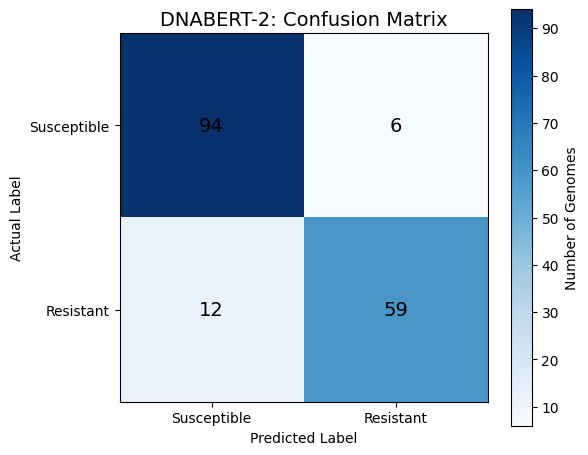

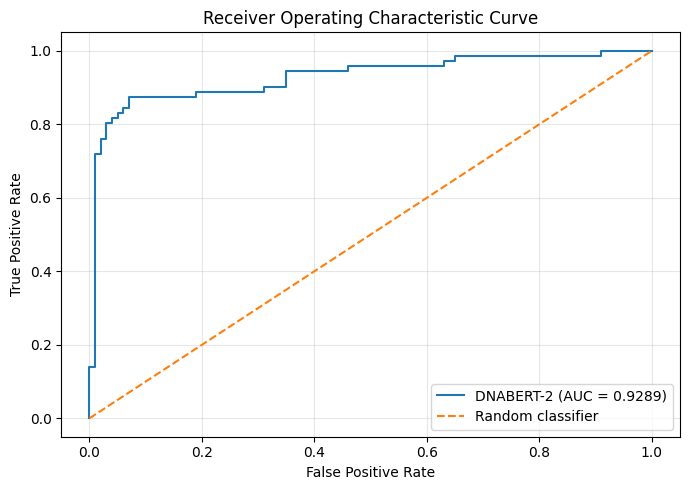

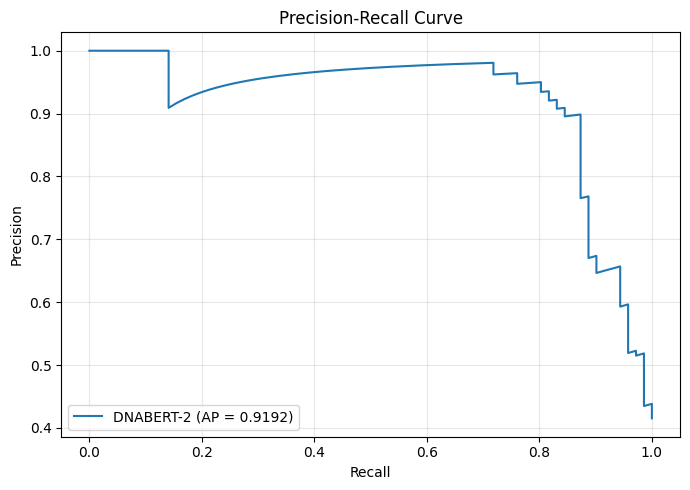

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

# 1. Performance metrics table
metrics_table = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "ROC-AUC",
        "PR-AUC",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Test Score": [
        accuracy_score(y_test, test_predictions),
        balanced_accuracy_score(y_test, test_predictions),
        roc_auc_score(y_test, test_probabilities),
        average_precision_score(y_test, test_probabilities),
        precision_score(y_test, test_predictions),
        recall_score(y_test, test_predictions),
        f1_score(y_test, test_predictions)
    ]
})

display(
    metrics_table.style.format({"Test Score": "{:.4f}"}).hide(axis="index")
)

# 2. Confusion matrix heatmap
cm = confusion_matrix(y_test, test_predictions)

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(cm, cmap="Blues")

ax.set_title("DNABERT-2: Confusion Matrix", fontsize=14)
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Susceptible", "Resistant"])
ax.set_yticklabels(["Susceptible", "Resistant"])

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=14,
            color="black"
        )

fig.colorbar(im, ax=ax, label="Number of Genomes")
plt.tight_layout()
plt.show()


# 3. ROC curve
fpr, tpr, _ = roc_curve(y_test, test_probabilities)
roc_auc = roc_auc_score(y_test, test_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"DNABERT-2 (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 4. Precision-Recall curve
precision_values, recall_values, _ = precision_recall_curve(
    y_test,
    test_probabilities
)

pr_auc = average_precision_score(y_test, test_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(
    recall_values,
    precision_values,
    label=f"DNABERT-2 (AP = {pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()